# tcspc_lifetime — calibration and batch fit, end to end

This notebook drives the library the way the GUI will:

1. **Calibrate:** read the N repetitions of the calibration dye and extract the IRF from them.
2. **Read the samples.**
3. **Choose the model:** number of components, which parameters are free, their ranges, and the fitting interval.
4. **Fit every sample**, and plot each fit with its residuals.
5. **Distribution of each free parameter** across the samples, with its mean and spread.

It runs on the simulated example data in `data/`, whose true values are known (see `data/README.md`). To use your own measurements, change the file paths in sections 1 and 2.

The library computes and never draws; every plot here is made in this notebook, as the GUI will.

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

import tcspc_lifetime
from tcspc_lifetime import Model, Parameter, read_decay, build_calibration, run_batch, SampleResult

print("tcspc_lifetime", tcspc_lifetime.__version__)

tcspc_lifetime 0.3.1


## 1 · Calibration

The calibration dye must be monoexponential, and measured in the same detection channel and filter range, with the same TCSPC settings, as the samples. Before summing the repetitions, the library checks that each one has the same shape as the others (a blind, model-free test). A repetition that fails is a different sample and is excluded; the rest are then re-tested among themselves.

The IRF is extracted from the sum. Its smoothing λ and cut m are chosen by **leaving one repetition out**: each candidate IRF is built from the other repetitions and scored on the one it never saw. The library also keeps the **leave-one-out IRFs**, which later measure how much each sample's result depends on the calibration's own noise.

In [2]:
# --- settings: your calibration files ---
CALIBRATION_FILES = sorted(Path("data/calibration").glob("*.csv"))
TIME_UNIT = "ns"                      # unit of the time column in the files: "ns" or "ps"

calibration_decays = [read_decay(path, time_unit=TIME_UNIT) for path in CALIBRATION_FILES]
for decay in calibration_decays:
    print(f"{decay.name}: {decay.counts.size} bins of {decay.bin_width_ns * 1000:.0f} ps, "
          f"peak {decay.counts.max():.0f} counts, total {decay.counts.sum():.3g}")

cal_01.csv: 250 bins of 100 ps, peak 10079 counts, total 2.46e+05
cal_02.csv: 250 bins of 100 ps, peak 10110 counts, total 2.46e+05
cal_03.csv: 250 bins of 100 ps, peak 10046 counts, total 2.47e+05
cal_04.csv: 250 bins of 100 ps, peak 10040 counts, total 2.81e+05
cal_05.csv: 250 bins of 100 ps, peak 10053 counts, total 2.46e+05


N = 5 repetitions; summed: ['cal_01.csv', 'cal_02.csv', 'cal_03.csv', 'cal_05.csv']
EXCLUDED cal_04.csv: shape test log10 p = -875 -> a different sample
shape-test p-values: {'cal_04.csv': '0', 'cal_01.csv': '0.29', 'cal_02.csv': '0.12', 'cal_03.csv': '0.79', 'cal_05.csv': '0.43'}
timing of each repetition (bins, vs median): {'cal_01.csv': '+0.08', 'cal_02.csv': '+0.07', 'cal_03.csv': '-0.07', 'cal_04.csv': '+2.61', 'cal_05.csv': '-0.25'}
IRF: λ = 0.04578 bins⁴, cut m = 23, 24 samples from 1.00 ns
λ and m chosen by: cross_validated; leave-one-out IRFs kept: 4
calibration dye lifetime (blind): 1.8695 ± 0.0020 ns


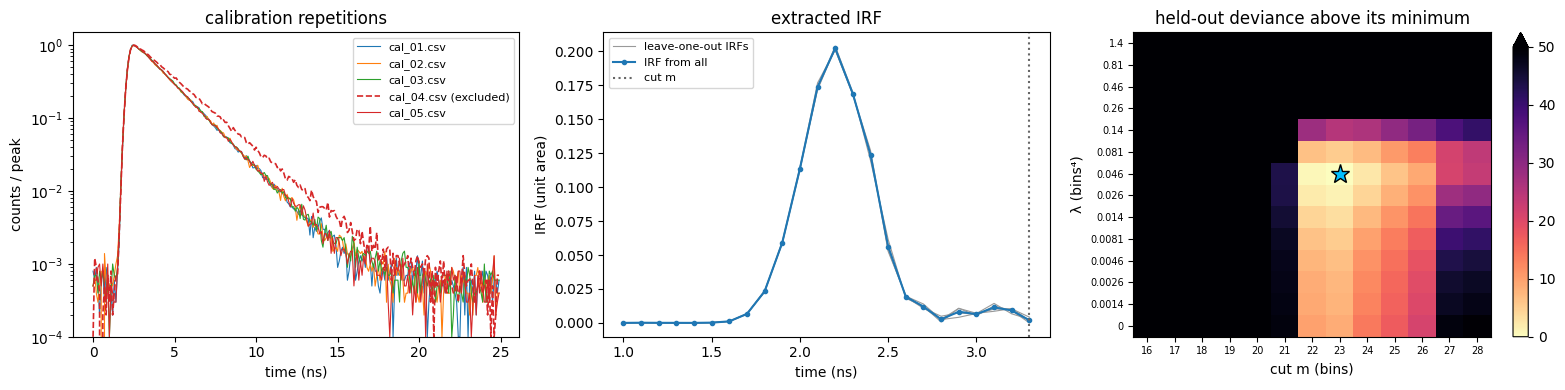

In [3]:
calibration = build_calibration(calibration_decays)

print(f"N = {calibration.n_repetitions} repetitions; summed: {calibration.accepted}")
for item in calibration.excluded:
    print(f"EXCLUDED {item['name']}: shape test log10 p = {item['log10_p_value']:.0f} -> a different sample")
print("shape-test p-values:", {name: f"{p:.2g}" for name, p in calibration.shape_test_p_values.items()})
print("timing of each repetition (bins, vs median):",
      {name: f"{offset:+.2f}" for name, offset in calibration.centroid_offsets_bins.items()})
print(f"IRF: λ = {calibration.best_lambda_bins4:.4g} bins⁴, cut m = {calibration.best_m_bin}, "
      f"{calibration.irf.size} samples from {calibration.time_ns[calibration.irf_start_bin]:.2f} ns")
print(f"λ and m chosen by: {calibration.selection}; leave-one-out IRFs kept: {len(calibration.jackknife_irfs)}")
print(f"calibration dye lifetime (blind): {calibration.tau_reference_ns:.4f} ± {calibration.tau_reference_error_ns:.4f} ns")

fig, (ax_reps, ax_irf, ax_score) = plt.subplots(1, 3, figsize=(16, 4))
excluded_names = [item["name"] for item in calibration.excluded]
for decay in calibration_decays:
    is_excluded = decay.name in excluded_names
    ax_reps.semilogy(decay.time_ns, decay.counts / decay.counts.max(), "--" if is_excluded else "-",
                     color="tab:red" if is_excluded else None, lw=1.2 if is_excluded else 0.8,
                     label=decay.name + (" (excluded)" if is_excluded else ""))
ax_reps.set(xlabel="time (ns)", ylabel="counts / peak", title="calibration repetitions", ylim=(1e-4, 1.5))
ax_reps.legend(fontsize=8)
irf_time = calibration.time_ns[calibration.irf_start_bin:calibration.irf_start_bin + calibration.irf.size]
for k, irf_k in enumerate(calibration.jackknife_irfs):
    ax_irf.plot(irf_time, irf_k, "-", lw=0.8, color="0.6", label="leave-one-out IRFs" if k == 0 else None)
ax_irf.plot(irf_time, calibration.irf, "o-", ms=3, color="tab:blue", label="IRF from all")
ax_irf.axvline(irf_time[-1], ls=":", color="0.4", label="cut m")
ax_irf.set(xlabel="time (ns)", ylabel="IRF (unit area)", title="extracted IRF")
ax_irf.legend(fontsize=8)
if calibration.selection_score_map is not None:
    score = calibration.selection_score_map - np.nanmin(calibration.selection_score_map)   # 0 at the chosen pair
    image = ax_score.pcolormesh(np.arange(calibration.m_grid_bin.size + 1) - 0.5,
                                np.arange(calibration.lambda_grid_bins4.size + 1) - 0.5,
                                np.minimum(score, 50), cmap="magma_r")
    i, j = np.unravel_index(np.argmin(score), score.shape)
    ax_score.plot(j, i, "*", ms=14, color="deepskyblue", markeredgecolor="k")
    ax_score.set_xticks(np.arange(calibration.m_grid_bin.size))
    ax_score.set_xticklabels([str(int(m)) for m in calibration.m_grid_bin], fontsize=7)
    ax_score.set_yticks(np.arange(calibration.lambda_grid_bins4.size))
    ax_score.set_yticklabels(["0"] + [f"{lam:.2g}" for lam in calibration.lambda_grid_bins4[1:]], fontsize=7)
    ax_score.set(xlabel="cut m (bins)", ylabel="λ (bins⁴)", title="held-out deviance above its minimum")
    fig.colorbar(image, ax=ax_score, extend="max")
plt.tight_layout()
plt.show()

calibration.save("calibration.json")           # reusable: Calibration.load("calibration.json")

## 2 · Samples

Same binning as the calibration (the library refuses anything else). The order of the files is taken as the acquisition order; the fitted shift then doubles as a drift monitor.

In [4]:
# --- settings: your sample files ---
SAMPLE_FILES = sorted(Path("data/samples").glob("*.csv"))

sample_decays = [read_decay(path, time_unit=TIME_UNIT) for path in SAMPLE_FILES]
print(f"{len(sample_decays)} samples: {sample_decays[0].name} ... {sample_decays[-1].name}")

12 samples: sample_01.csv ... sample_12.csv


## 3 · The model

Every option of the GUI's decay-parameter panel (modelled on SPCImage NG) is set here:

| Setting | Meaning |
|---|---|
| `n_components` | 1, 2 or 3 exponential components |
| `lifetimes_ns` | one `Parameter` per component: `value` (start, or the value if fixed), `fixed`, `lower`, `upper` in ns. Leave `value=None` to let a coarse search find the start. Giving each component its own range keeps the labels τ₁, τ₂ stable across samples. |
| `shift_bins` | IRF timing relative to the calibration, in bins (sub-bin). Default: free in [−3, 3]. |
| `scatter` | an IRF-shaped, instantaneous component (scattered excitation light), in counts. Default: fixed at 0. Kept ≥ 0 when free. |
| `offset` | flat background, counts per bin. Default: free. Kept ≥ 0. |
| `fit_start_ns`, `fit_end_ns` | fitting interval. The model is always computed over the whole histogram; only bins inside the interval enter the likelihood. `None` = from the calibration window's start to the end. |

Amplitudes are always free, as in SPCImage. Example: to fix τ₁ at a known value, use `Parameter(0.8, fixed=True)`.

In [5]:
# --- settings: the model ---
MODEL = Model(
    n_components=2,
    lifetimes_ns=[
        Parameter(value=None, fixed=False, lower=0.2, upper=1.8),    # τ1 (ns)
        Parameter(value=None, fixed=False, lower=1.8, upper=8.0),    # τ2 (ns)
    ],
    shift_bins=Parameter(value=0.0, fixed=False, lower=-3.0, upper=3.0),
    scatter=Parameter(value=0.0, fixed=True),
    offset=Parameter(value=None, fixed=False),
    fit_start_ns=1.0,
    fit_end_ns=24.9,
)
MODEL

Model(n_components=2, lifetimes_ns=[Parameter(value=None, fixed=False, lower=0.2, upper=1.8), Parameter(value=None, fixed=False, lower=1.8, upper=8.0)], shift_bins=Parameter(value=0.0, fixed=False, lower=-3.0, upper=3.0), scatter=Parameter(value=0.0, fixed=True, lower=None, upper=None), offset=Parameter(value=None, fixed=False, lower=None, upper=None), fit_start_ns=1.0, fit_end_ns=24.9)

## 4 · Fit every sample

Each sample is one Poisson maximum-likelihood fit. Every parameter gets three errors:

- **statistical:** the Fisher error from the sample's own photons;
- **IRF:** the jackknife error, from refitting the sample with each leave-one-out IRF — the calibration's photon noise, shared by every sample of the batch;
- **total:** the two combined, √(stat² + IRF²). The table shows value ± total.

In [6]:
def show_progress(done, total, name):
    print(f"\r{done}/{total} fitted ({name})", end="")

results = run_batch(sample_decays, calibration, MODEL, progress=show_progress)
fits = [r for r in results if isinstance(r, SampleResult)]
for failure in (r for r in results if not isinstance(r, SampleResult)):
    print(f"\nFAILED {failure.decay_name}: {failure.error_message}")
print()

LABELS = {"tau_1_ns": "τ1 (ns)", "tau_2_ns": "τ2 (ns)", "tau_3_ns": "τ3 (ns)",
          "amplitude_1_percent": "a1 (%)", "amplitude_2_percent": "a2 (%)", "amplitude_3_percent": "a3 (%)",
          "shift_bins": "shift (bins)", "scatter_counts": "scatter (counts)",
          "offset_counts_per_bin": "offset (counts/bin)", "tau_mean_intensity_ns": "τ intensity-weighted (ns)",
          "tau_mean_amplitude_ns": "τ amplitude-weighted (ns)"}
ALSO_SHOW = ["tau_mean_intensity_ns"]        # derived quantities to add to the table and the distributions


def shown_parameters(result):
    # the free fitted parameters; amplitudes as percentages (they are always free)
    n = result.model["n_components"]
    names = [f"tau_{i + 1}_ns" for i in range(n) if result.parameters[f"tau_{i + 1}_ns"]["free"]]
    if n > 1:
        names += [f"amplitude_{i + 1}_percent" for i in range(n)]
    names += [p for p in ("shift_bins", "scatter_counts", "offset_counts_per_bin") if result.parameters[p]["free"]]
    return names + [p for p in ALSO_SHOW if n > 1]


def with_error(result, name):
    error = result.total_error(name) if result.total_error(name) is not None else result.error(name)
    return f"{result.value(name):.4g} ± {error:.2g}" if error is not None else f"{result.value(name):.4g}"


names = shown_parameters(fits[0])
header = f"{'sample':14s}" + "".join(f"{LABELS[n]:>24s}" for n in names) + f"{'dev/dof':>9s}{'Σz²/blocks':>12s}"
print(header)
for r in fits:
    print(f"{r.decay_name:14s}" + "".join(f"{with_error(r, n):>24s}" for n in names)
          + f"{r.deviance_per_dof:9.3f}{r.curvature_sum_z2:8.1f}/{r.curvature_blocks}")

1/12 fitted (sample_01.csv)

2/12 fitted (sample_02.csv)

3/12 fitted (sample_03.csv)

4/12 fitted (sample_04.csv)

5/12 fitted (sample_05.csv)

6/12 fitted (sample_06.csv)

... (2 outputs left out)

9/12 fitted (sample_09.csv)

10/12 fitted (sample_10.csv)

11/12 fitted (sample_11.csv)

12/12 fitted (sample_12.csv)
sample                         τ1 (ns)                 τ2 (ns)                  a1 (%)                  a2 (%)            shift (bins)     offset (counts/bin)τ intensity-weighted (ns)  dev/dof  Σz²/blocks
sample_01.csv           0.8138 ± 0.014           3.199 ± 0.015               60 ± 0.38               40 ± 0.38        -0.00392 ± 0.013            8.363 ± 0.87           2.54 ± 0.0068    1.170    22.9/24
sample_02.csv            0.791 ± 0.013           3.201 ± 0.015            60.17 ± 0.37            39.83 ± 0.37         0.04371 ± 0.013            6.648 ± 0.84          2.546 ± 0.0068    1.030    16.9/24
sample_03.csv           0.7974 ± 0.014           3.183 ± 0.015            59.49 ± 0.38            40.51 ± 0.38         0.08216 ± 0.013            7.595 ± 0.84          2.542 ± 0.0068    1.024    26.0/24
sample_04.csv           0.8264 ± 0.015           3.221 ± 0.015            60.03 ± 0.38            39.97 ± 0.38         0.08139 ± 0.013            6.382 ± 0.8

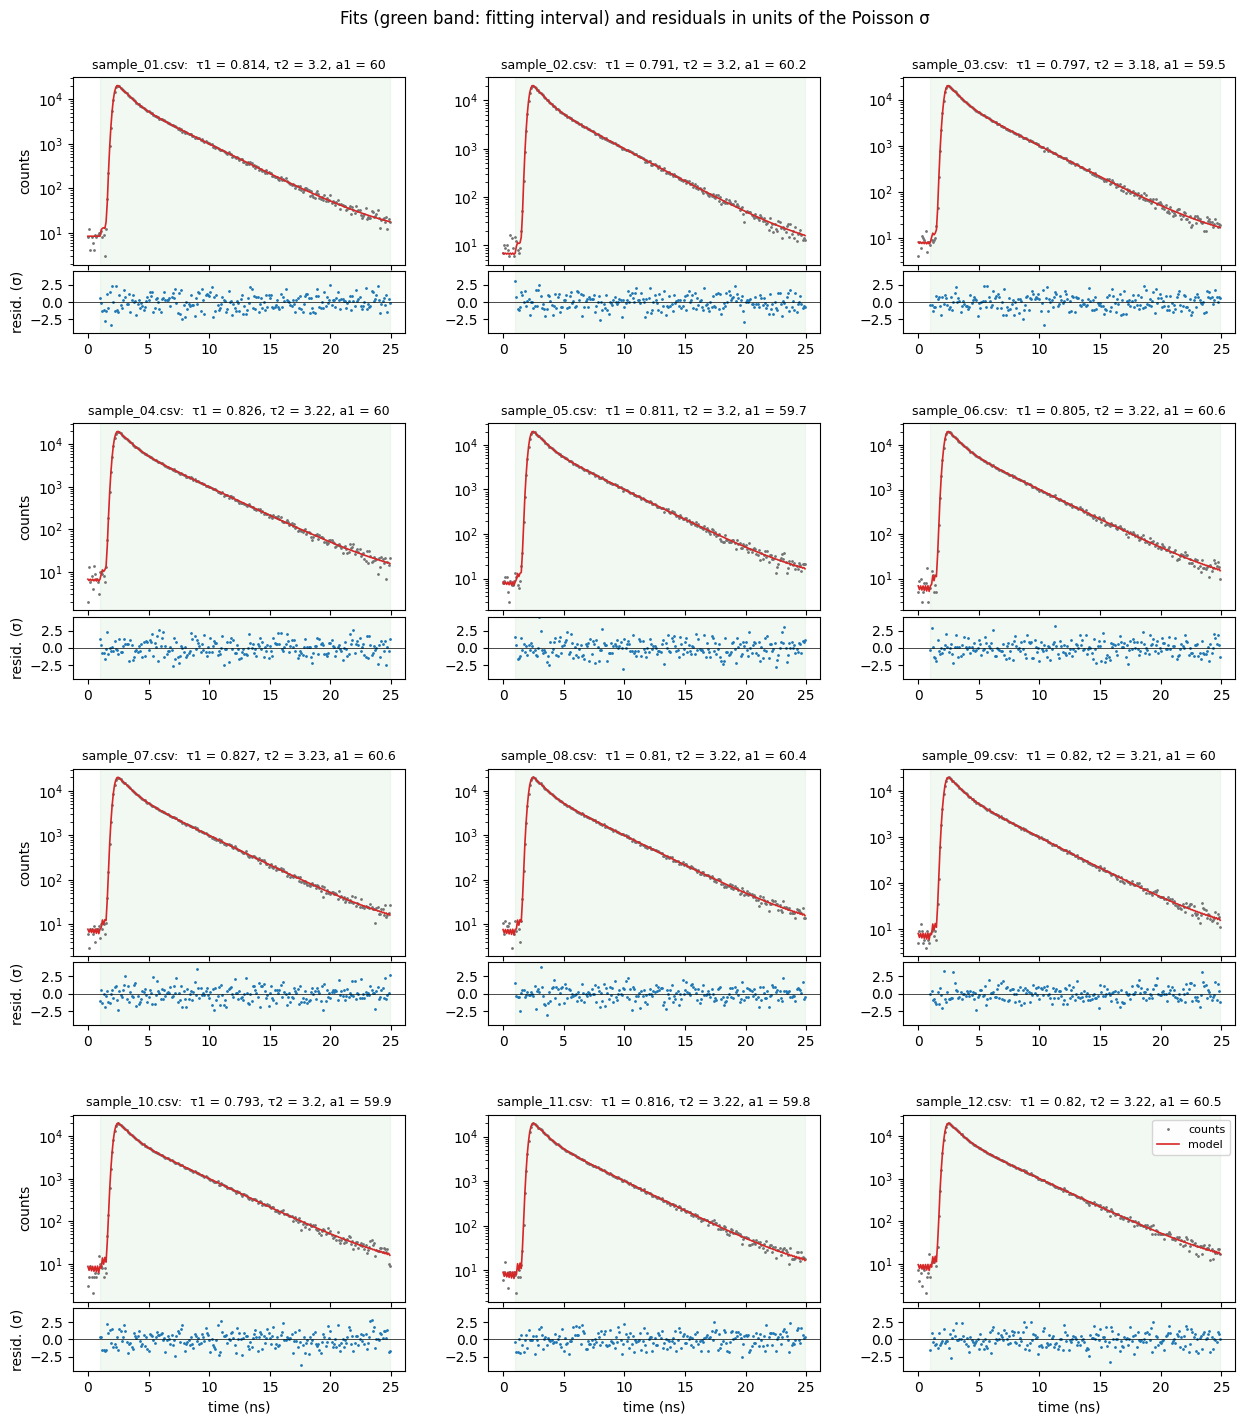

In [7]:
n_columns = 3
n_rows = int(np.ceil(len(fits) / n_columns))
fig = plt.figure(figsize=(5 * n_columns, 4.2 * n_rows))
outer = fig.add_gridspec(n_rows, n_columns, hspace=0.35, wspace=0.25)
for k, r in enumerate(fits):
    row, column = divmod(k, n_columns)
    pair = outer[row, column].subgridspec(2, 1, height_ratios=[3, 1], hspace=0.05)   # fit above residuals
    top = fig.add_subplot(pair[0])
    bottom = fig.add_subplot(pair[1], sharex=top)
    inside = r.fit_mask
    top.semilogy(r.time_ns, np.maximum(r.counts, 0.5), ".", ms=2, color="0.45", label="counts")
    top.semilogy(r.time_ns, r.model_counts, "-", lw=1.2, color="tab:red", label="model")
    bottom.plot(r.time_ns[inside], r.residuals_sigma[inside], ".", ms=2, color="tab:blue")
    for ax in (top, bottom):
        ax.axvspan(r.time_ns[inside][0], r.time_ns[inside][-1], color="tab:green", alpha=0.06)
    bottom.axhline(0, color="k", lw=0.5)
    bottom.set_ylim(-4.5, 4.5)
    top.set_title(f"{r.decay_name}:  " + ", ".join(f"{LABELS[n].split(' ')[0]} = {r.value(n):.3g}"
                                                    for n in names if n.startswith(("tau_1", "tau_2", "amplitude_1"))),
                  fontsize=9)
    top.tick_params(labelbottom=False)
    if column == 0:
        top.set_ylabel("counts")
        bottom.set_ylabel("resid. (σ)")
    if row == n_rows - 1:
        bottom.set_xlabel("time (ns)")
top.legend(fontsize=8)
fig.suptitle("Fits (green band: fitting interval) and residuals in units of the Poisson σ", y=0.92)
plt.show()

## 5 · Distribution of each free parameter

For each parameter: the values of all samples, their **mean** and **spread** (standard deviation, SD), and two typical errors for comparison:

- **mean statistical error:** if the spread is close to it, the samples differ only by photon noise; a much larger spread points to real differences between samples (or a drift).
- **mean IRF error:** the calibration's noise is common to all samples, so it shifts every value together. It does not appear in the spread, but it limits how well the *mean* is known: the mean cannot be trusted to better than about this, however many samples are averaged.

`TRUE_VALUES` marks the known truth of the example data; set it to `{}` for your own measurements.

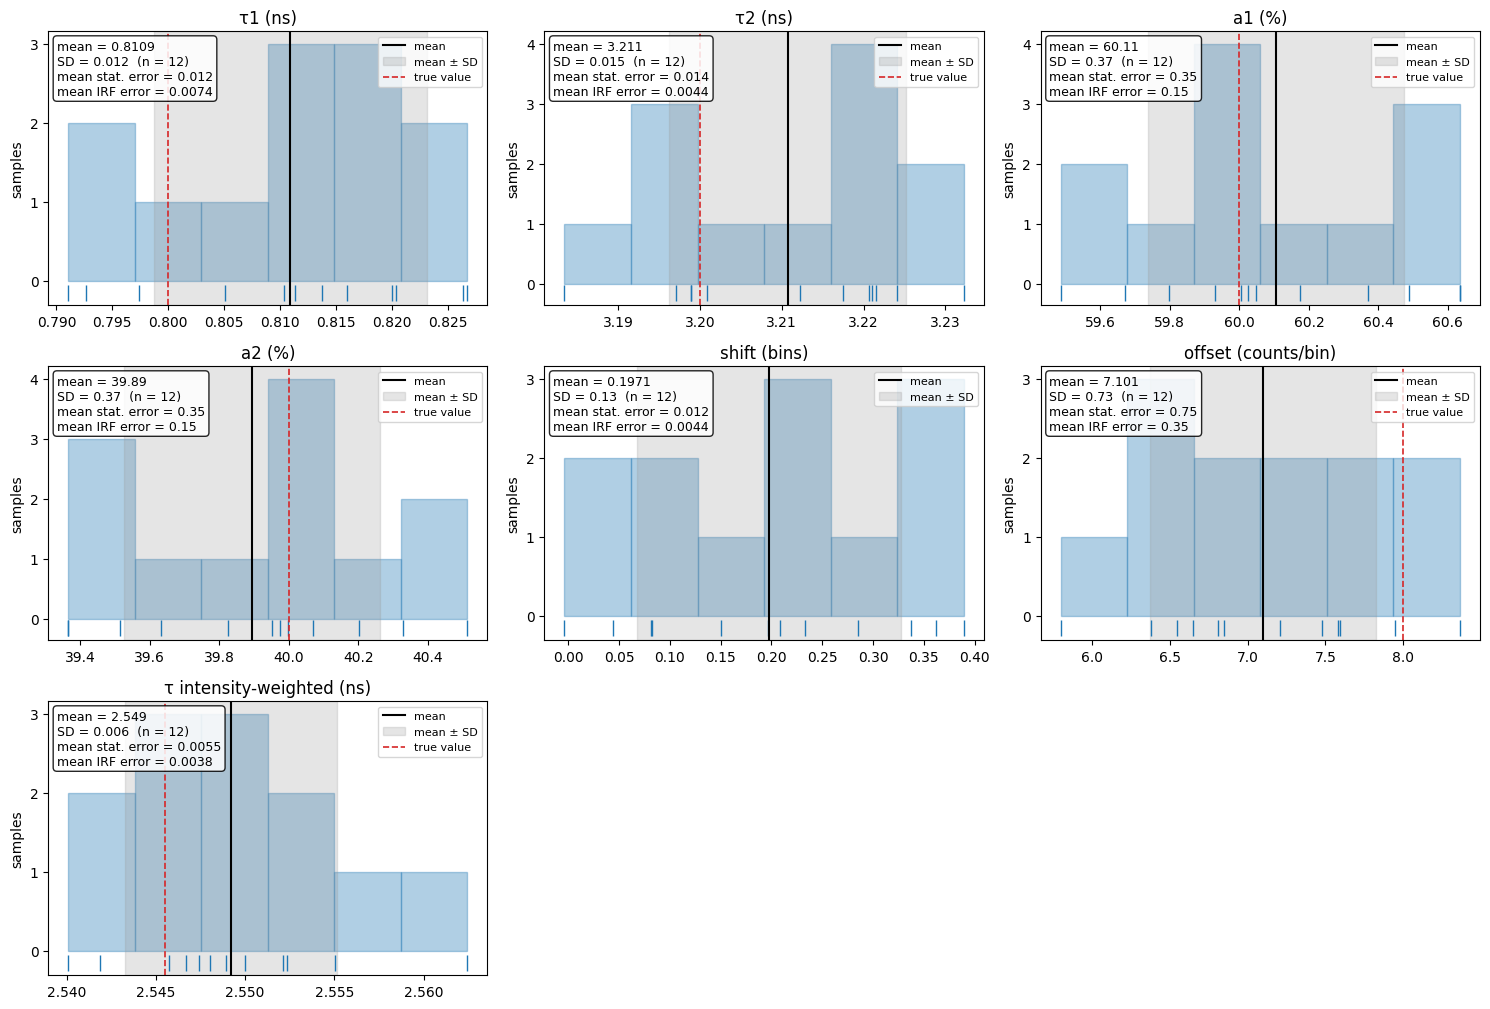

In [8]:
TRUE_VALUES = {"tau_1_ns": 0.8, "tau_2_ns": 3.2, "amplitude_1_percent": 60.0, "amplitude_2_percent": 40.0,
               "offset_counts_per_bin": 8.0, "tau_mean_intensity_ns": 2.5455}

n_columns = 3
n_rows = int(np.ceil(len(names) / n_columns))
fig, axes = plt.subplots(n_rows, n_columns, figsize=(5 * n_columns, 3.4 * n_rows), squeeze=False)
for ax, name in zip(axes.flat, names):
    values = np.array([r.value(name) for r in fits])
    errors = np.array([r.error(name) if r.error(name) is not None else np.nan for r in fits])
    irf_errors = np.array([r.irf_error(name) if r.irf_error(name) is not None else np.nan for r in fits])
    mean, spread = values.mean(), values.std(ddof=1)
    ax.hist(values, bins=min(10, max(4, len(values) // 2)), color="tab:blue", alpha=0.35, edgecolor="tab:blue")
    ax.plot(values, np.full(values.size, -0.15), "|", color="tab:blue", ms=12)          # each sample
    ax.axvline(mean, color="k", lw=1.5, label="mean")
    ax.axvspan(mean - spread, mean + spread, color="0.6", alpha=0.25, label="mean ± SD")
    if name in TRUE_VALUES:
        ax.axvline(TRUE_VALUES[name], color="tab:red", ls="--", lw=1.2, label="true value")
    ax.set_title(LABELS[name])
    ax.set_ylabel("samples")
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.text(0.02, 0.97, f"mean = {mean:.4g}\nSD = {spread:.2g}  (n = {values.size})\n"
                        f"mean stat. error = {np.nanmean(errors):.2g}\nmean IRF error = {np.nanmean(irf_errors):.2g}",
            transform=ax.transAxes, va="top", fontsize=9,
            bbox=dict(boxstyle="round", facecolor="white", alpha=0.85))
    ax.legend(fontsize=8, loc="upper right")
for ax in list(axes.flat)[len(names):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

### Drift monitor

The fitted shift, in acquisition order. A trend means the timing drifted after the calibration was measured.

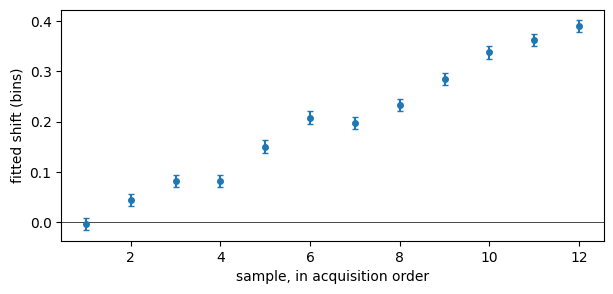

trend: +0.394 bins from first to last sample


In [9]:
shifts = np.array([r.value("shift_bins") for r in fits])
shift_errors = np.array([r.error("shift_bins") for r in fits])
fig, ax = plt.subplots(figsize=(7, 3))
ax.errorbar(np.arange(1, len(fits) + 1), shifts, yerr=shift_errors, fmt="o", ms=4, capsize=2)
ax.set(xlabel="sample, in acquisition order", ylabel="fitted shift (bins)")
ax.axhline(0, color="k", lw=0.5)
plt.show()
slope = np.polyfit(np.arange(len(fits)), shifts, 1)[0]
print(f"trend: {slope * (len(fits) - 1):+.3f} bins from first to last sample")

## Notes

- **Your own data:** change `CALIBRATION_FILES`, `SAMPLE_FILES`, `TIME_UNIT`, `MODEL` and `TRUE_VALUES`; nothing else.
- **Results for the GUI:** every result converts to JSON with `result.to_dict()`; the calibration is saved in `calibration.json`.
- **What the errors include:** the sample's photon noise (statistical) and the calibration IRF's photon noise (jackknife). Validated on 16 simulated experiments: the jackknife matches the scatter the calibration causes (e.g. τ₂: 0.0065 ns both), and the combined errors have the right scale. Not included: a wrong model.